In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from skimage import io, filters, morphology, measure, segmentation
from skimage.feature import peak_local_max
from skimage.segmentation import find_boundaries
from scipy import ndimage as ndi

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GroupShuffleSplit

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
    
)

from skimage import segmentation, exposure

# Functions

In [2]:
def plot_image(image, clean_mask, labels, df_subset,
               mode="image", figsize=(8, 8)):

    # Get original segmentation labels from DataFrame subset
    selected_ids = df_subset["label"].astype(int).to_numpy()

    # Keep only selected objects
    selected_labels = np.where(
        np.isin(labels, selected_ids),
        labels,
        0
    )

    # Choose background
    if mode == "image":
        background = exposure.rescale_intensity(
            image.astype(float),
            in_range="image",
            out_range=(0, 1)
        )

    elif mode == "mask":
        background = clean_mask.astype(float)

    else:
        raise ValueError("mode must be 'image' or 'mask'")

    # Plot
    fig, ax = plt.subplots(figsize=figsize)

    ax.imshow(
        segmentation.mark_boundaries(
            background,
            selected_labels,
            color=(1, 0, 0)
        )
    )

    ax.set_title(
        f"Selected objects: {len(selected_ids)}"
    )

    ax.axis("off")

    plt.tight_layout()
    plt.show()

In [3]:
def show_objects_from_list(image, labels, df, indexes, padding=10, ncols=3):

    if np.isscalar(indexes):
        indexes = [indexes]

    indexes = list(indexes)

    regions = {
        r.label: r
        for r in measure.regionprops(labels)
    }

    if not indexes:
        print("No objects selected.")
        return

    nrows = int(np.ceil(len(indexes) / ncols))

    fig, axes = plt.subplots(
        nrows,
        ncols,
        figsize=(ncols * 3.5, nrows * 3.5),
        squeeze=False
    )

    for ax in axes.flat:
        ax.axis("off")

    for i, idx in enumerate(indexes):

        row = df.loc[idx]

        # Segmentation label
        object_id = int(row["label"])

        region = regions.get(object_id)

        if region is None:
            print(f"Object {object_id} not found.")
            continue

        min_row, min_col, max_row, max_col = region.bbox

        y0 = max(0, min_row - padding)
        y1 = min(image.shape[0], max_row + padding)

        x0 = max(0, min_col - padding)
        x1 = min(image.shape[1], max_col + padding)

        crop = image[y0:y1, x0:x1]
        mask_crop = labels[y0:y1, x0:x1] == object_id

        r = i // ncols
        c = i % ncols

        ax = axes[r, c]

        ax.imshow(crop, cmap="gray")

        ax.contour(
            mask_crop.astype(float),
            levels=[0.5],
            colors="red",
            linewidths=1
        )

        # Original index from full DataFrame
        ax.set_title(
            f"Label: {idx}\n"
            f"Area: {row['area']:.2f} | "
            f"Circularity: {row['circularity']:.2f}",
            fontsize=10
        )

    plt.tight_layout()
    plt.show()

In [4]:
def objects_show(subset, image, labels,
                 crop_size=40, ncols=5):

    n = len(subset)

    if n == 0:
        print("No objects to display.")
        return

    nrows = int(np.ceil(n / ncols))

    fig, axes = plt.subplots(
        nrows, ncols,
        figsize=(ncols * 2.5, nrows * 2.5),
        squeeze=False
    )

    H, W = image.shape[:2]

    for ax, (_, row) in zip(axes.flat, subset.iterrows()):

        x = int(round(row["centroid-1"]))
        y = int(round(row["centroid-0"]))

        # Original watershed object ID
        object_id = int(row["label"])

        half = crop_size // 2

        x1 = max(0, x - half)
        x2 = min(W, x + half)
        y1 = max(0, y - half)
        y2 = min(H, y + half)

        # Crop original image
        crop = image[y1:y2, x1:x2]

        # Crop watershed labels
        labels_crop = labels[y1:y2, x1:x2]

        # Select only this object
        mask = labels_crop == object_id

        # Find original watershed boundary
        boundary = find_boundaries(mask, mode="inner")

        # Show microscopy image
        ax.imshow(crop, cmap="gray")

        # Overlay boundary in red
        ax.contour(
            mask.astype(float),
            levels=[0.5],
            colors="red",
            linewidths=1
        )

        ax.set_title(
            f"Index: {row.name}\n"
            f"Circularity: {row['circularity']:.2f}\n"
            f"Area: {row['area']:.2f}",
            fontsize=9
        )

        ax.axis("off")

    # Hide unused panels
    for ax in axes.flat[n:]:
        ax.axis("off")

    plt.tight_layout()
    plt.show()

# Import data

## Image downloading

Image shape: (512, 512)
Data type: uint16


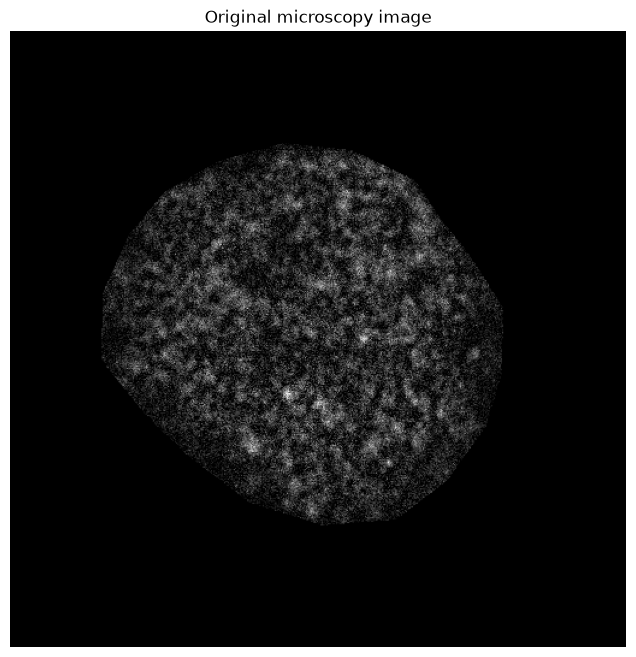

In [5]:
image_path = "0243.tif"

image = io.imread(image_path)

print("Image shape:", image.shape)
print("Data type:", image.dtype)

fig, ax = plt.subplots(figsize=(8, 8))

ax.imshow(image, cmap="gray")
ax.set_title("Original microscopy image")
ax.axis("off")

plt.show()

# Thresholding

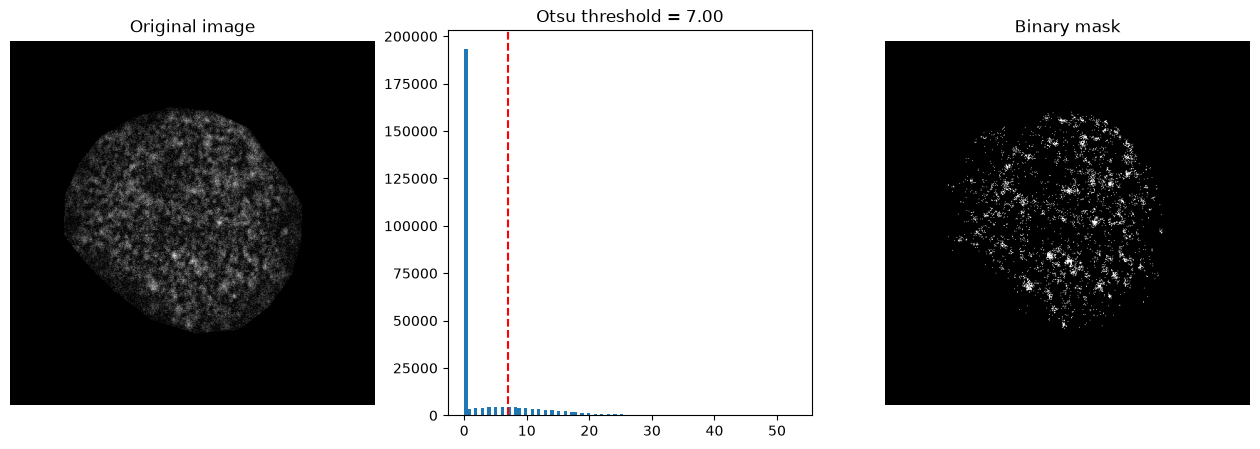

In [8]:
threshold = filters.threshold_otsu(image)
threshold_factor = 3

binary_mask = image > threshold * threshold_factor

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

axes[0].imshow(image, cmap="gray")
axes[0].set_title("Original image")

axes[1].hist(image.ravel(), bins=100)
axes[1].axvline(threshold, color="red", linestyle="--")
axes[1].set_title(f"Otsu threshold = {threshold:.2f}")

axes[2].imshow(binary_mask, cmap="gray")
axes[2].set_title("Binary mask")

for ax in [axes[0], axes[2]]:
    ax.axis("off")

# Cleaning

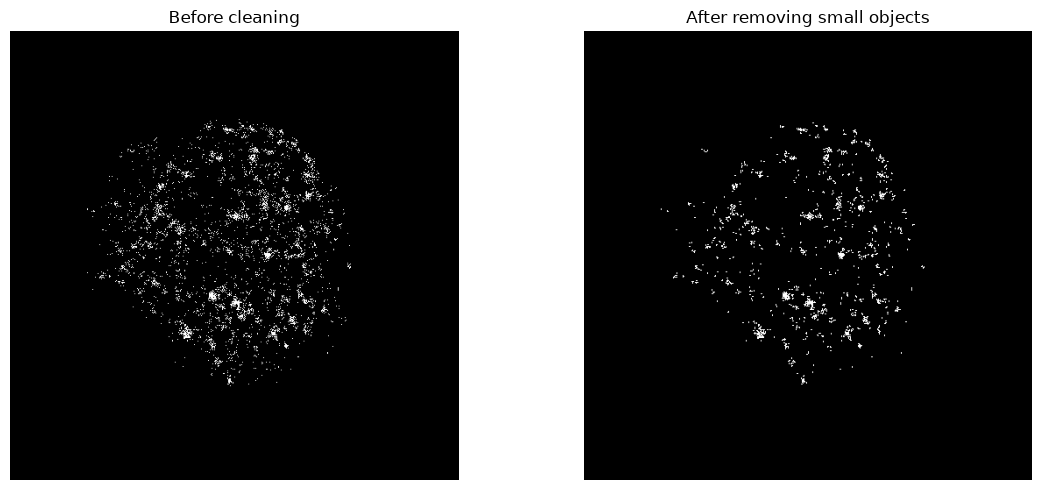

In [9]:
min_area = 2  # pixels

clean_mask = morphology.remove_small_objects(
    binary_mask,
    min_size=min_area
)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].imshow(binary_mask, cmap="gray")
axes[0].set_title("Before cleaning")

axes[1].imshow(clean_mask, cmap="gray")
axes[1].set_title("After removing small objects")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

# Watersheding

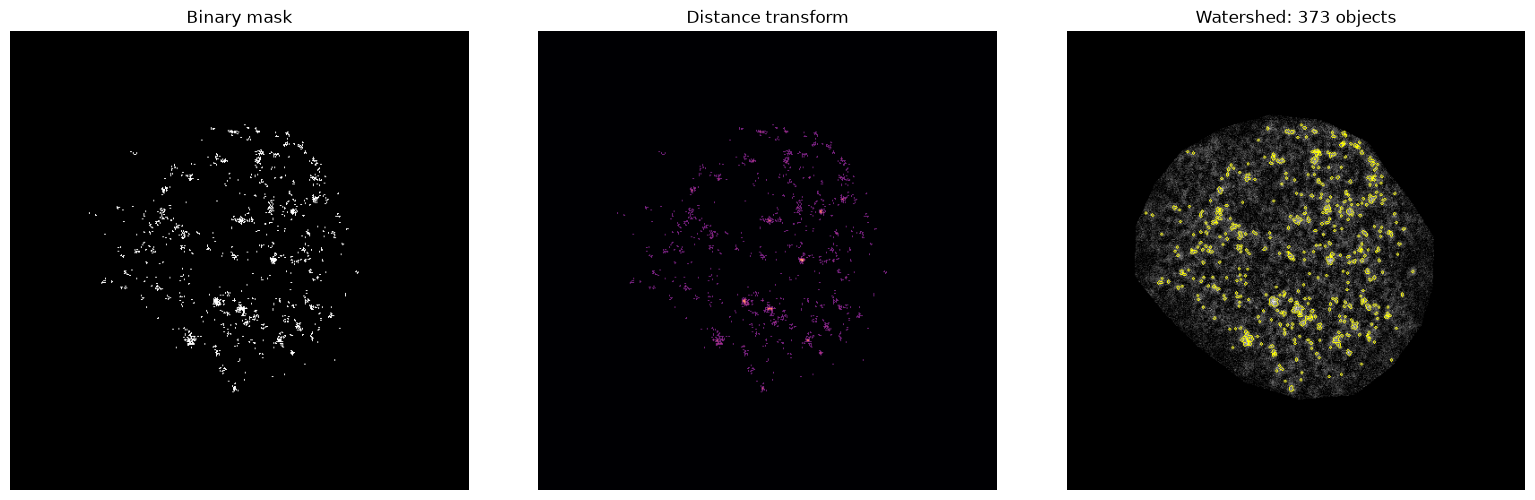

In [10]:
image_float = image.astype(np.float32)

distance = ndi.distance_transform_edt(clean_mask)

# Detect candidate centers
coordinates = peak_local_max(
    distance,
    min_distance=5,
    labels=clean_mask
)

markers = np.zeros_like(clean_mask, dtype=np.int32)

for i, (y, x) in enumerate(coordinates, start=1):
    markers[y, x] = i

labels = segmentation.watershed(
    -distance,
    markers,
    mask=clean_mask
)

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

axes[0].imshow(clean_mask, cmap="gray")
axes[0].set_title("Binary mask")

axes[1].imshow(distance, cmap="magma")
axes[1].set_title("Distance transform")

axes[2].imshow(
    segmentation.mark_boundaries(
        image_float / (image_float.max() + 1e-8),
        labels
    )
)
axes[2].set_title(f"Watershed: {labels.max()} objects")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

# Features analysis

In [ ]:
properties = measure.regionprops_table(
    labels,
    intensity_image=image_float,
    properties=[
        "label",
        "area",
        "centroid",
        "equivalent_diameter_area",
        "eccentricity",
        "solidity",
        "perimeter",
        "mean_intensity",
        "max_intensity",
        "min_intensity"
    ]
)

df = pd.DataFrame(properties)

# Circularity: 1 means approximately circular
df["circularity"] = (
    4 * np.pi * df["area"]
    / (df["perimeter"] ** 2 + 1e-8)
)

df["image_id"] = Path(image_path).name

display(df.head())

print("Total detected objects:", len(df))

,label,area,centroid-0,centroid-1,equivalent_diameter_area,eccentricity,solidity,perimeter,mean_intensity,max_intensity,min_intensity,circularity,image_id
0,1,42.0,254.976190,293.357143,7.312733,0.492020,0.763636,29.556349,31.690475,46.0,22.0,0.604168,0243.tif
1,2,31.0,201.129032,315.580645,6.282549,0.686198,0.794872,19.520815,28.387096,51.0,22.0,1.022294,0243.tif
2,3,60.0,301.550000,230.466667,8.740387,0.567074,0.714286,40.798990,32.883335,53.0,22.0,0.452963,0243.tif
3,4,66.0,309.590909,257.318182,9.166996,0.601968,0.616822,44.763456,30.181818,49.0,22.0,0.413911,0243.tif
4,5,17.0,177.117647,170.647059,4.652426,0.885615,0.850000,14.449747,26.882353,38.0,22.0,1.023148,0243.tif


Total detected objects: 373


In [ ]:
# Save the DataFrame to a CSV file
df.to_csv("0243.csv", index=False)

### Descriptive statistics of data

In [13]:
df.describe()

,label,area,centroid-0,centroid-1,equivalent_diameter_area,eccentricity,solidity,perimeter,mean_intensity,max_intensity,min_intensity,circularity
count,373.000000,373.000000,373.000000,373.000000,373.000000,373.000000,373.000000,373.000000,373.000000,373.000000,373.000000,3.730000e+02
mean,187.000000,5.316354,245.529391,256.418785,2.327790,0.901233,0.926065,3.888791,25.784152,29.471850,23.136729,1.125246e+09
std,107.820066,7.375612,70.179128,69.585961,1.163621,0.143965,0.119487,6.120012,2.291415,5.408316,1.659144,1.251428e+09
min,1.000000,2.000000,104.000000,88.000000,1.595769,0.000000,0.558442,0.000000,22.000000,22.000000,22.000000,3.976256e-01
25%,94.000000,2.000000,193.000000,194.500000,1.595769,0.816497,0.833333,0.000000,24.000000,26.000000,22.000000,2.443504e+00
50%,187.000000,3.000000,243.666667,267.500000,1.954410,0.960141,1.000000,3.207107,25.500000,28.000000,23.000000,4.887008e+00
75%,280.000000,5.000000,302.000000,313.000000,2.523133,1.000000,1.000000,5.207107,27.500000,33.000000,24.000000,2.513274e+09
max,373.000000,66.000000,398.375000,385.666667,9.166996,1.000000,1.000000,44.763456,34.000000,53.000000,31.000000,2.513274e+09


## Feature subset and visualization

In [ ]:
subset = df[(df['area'] > 2.5)]

plot_image(
    image,
    clean_mask,
    labels,
    subset,
    mode="image"
)

In [16]:
inxs = df[df["perimeter"] > 25].index.tolist()

print("Number of selected objects:", len(inxs))

Number of selected objects: 7


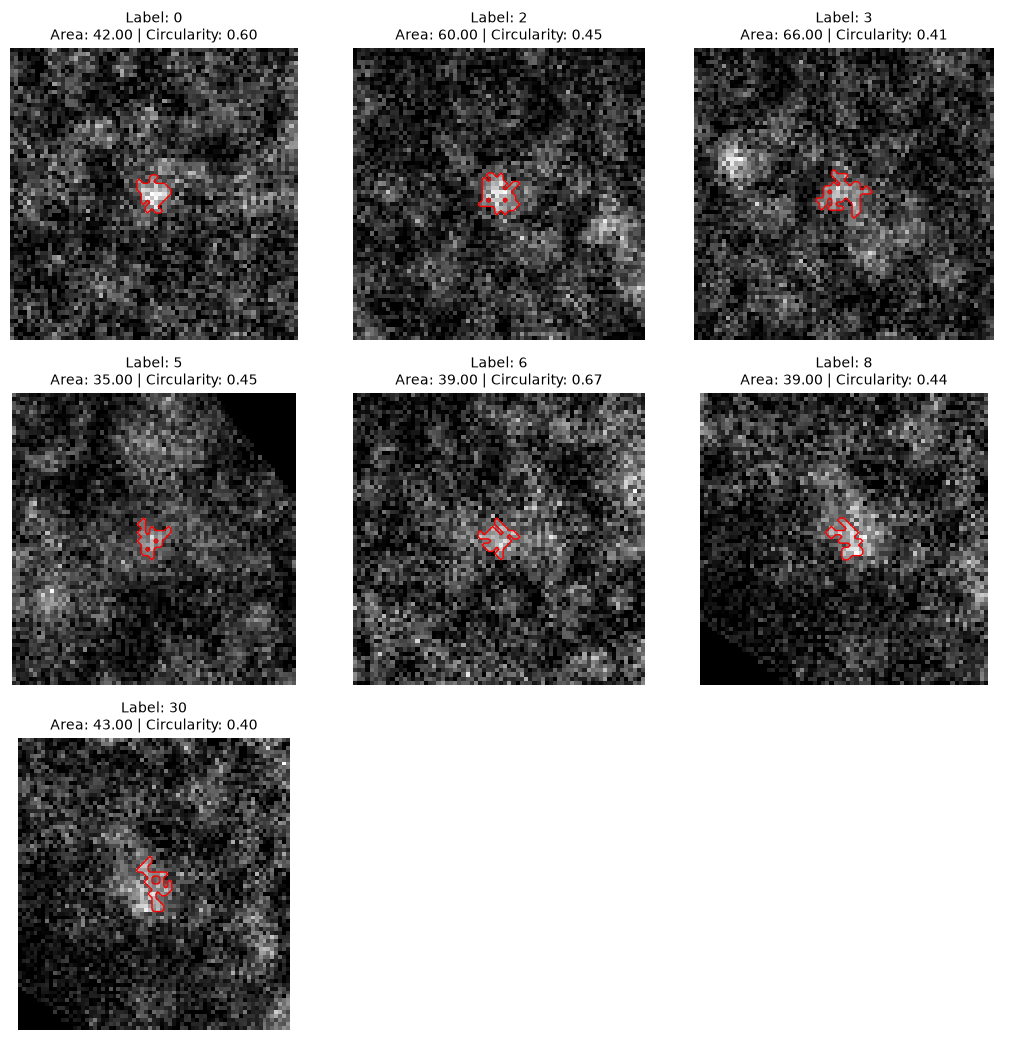

In [17]:
show_objects_from_list(
    image,
    labels,
    df,
    inxs,
    padding=30,
    ncols=3
)

# Randon Forest

In [20]:
df1 = pd.read_csv("training_data_Outsu/0243_labelled.csv",  sep=";", encoding="cp1252")
df2 = pd.read_csv("training_data_Outsu/0244_labelled.csv",  sep=";", encoding="cp1252")

dfs = [df1, df2]

In [ ]:
df_combined = pd.concat(dfs, ignore_index=True)

df = df_combined[
    df_combined["Class"].isin(["foci", "aggregate"])
].reset_index(drop=True)

df.shape

KeyError: 'foci_SD'

In [ ]:
df.columns

In [ ]:
# Features for classification
features = [
    "area",
    "equivalent_diameter_area",
    "eccentricity",
    "solidity",
    "perimeter",
    "mean_intensity",
    "max_intensity",
    "min_intensity",
    "circularity",
]

# Copy original DataFrame
data = df.copy()

# Clean class labels
data["Class"] = (
    data["Class"]
    .astype("string")
    .str.strip()
    .str.lower()
)

# Convert features to numeric
for feature in features:
    data[feature] = pd.to_numeric(
        data[feature],
        errors="coerce"
    )

# Manually labeled objects
labeled = data[
    data["Class"].isin(["foci", "aggregate"])
].dropna(subset=features).copy()

print("Training samples:")
print(labeled["Class"].value_counts())

In [ ]:
# Model training
X = labeled[features]
y = labeled["Class"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

rf = RandomForestClassifier(
    n_estimators=300,
    max_depth=8,
    min_samples_leaf=3,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf.fit(X_train, y_train)


In [ ]:
y_pred = rf.predict(X_test)

print(classification_report(
    y_test,
    y_pred,
    zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    cmap="Blues"
)

plt.title("Random Forest — Confusion Matrix")
plt.show()

In [ ]:
importance = pd.Series(
    rf.feature_importances_,
    index=features
).sort_values()

fig, ax = plt.subplots(figsize=(7, 4))

importance.plot.barh(ax=ax)

ax.set_xlabel("Feature importance")
ax.set_title("Random Forest Feature Importance")

plt.tight_layout()
plt.show()

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.inspection import permutation_importance

result = permutation_importance(
    rf,
    X_test,
    y_test,
    n_repeats=50,
    random_state=42,
    scoring="balanced_accuracy"
)

importance_df = pd.DataFrame({
    "feature": X_test.columns,
    "importance": result.importances_mean,
    "std": result.importances_std
})

importance_df = importance_df.sort_values("importance")

print(importance_df)

fig, ax = plt.subplots(figsize=(8, 5))

ax.barh(
    importance_df["feature"],
    importance_df["importance"],
    xerr=importance_df["std"],
    color="lightblue",
    edgecolor="black",
    capsize=4
)

ax.axvline(0, color="black", linewidth=1)

ax.set_xlabel("Decrease in balanced accuracy")
ax.set_title("Permutation Feature Importance")

plt.tight_layout()
plt.show()

# Information about features

### Feature distribution

In [ ]:
features = [
    "area",
    "equivalent_diameter_area",
    "perimeter",
    "mean_intensity",
    "max_intensity",
    "circularity",
]

# Clean column names
df = df.copy()
df.columns = df.columns.str.strip().str.lower()

# Convert features to numeric
df[features] = df[features].apply(
    pd.to_numeric,
    errors="coerce"
)

fig, axes = plt.subplots(2, 3, figsize=(15, 9))

for ax, feature in zip(axes.flat, features):

    sns.violinplot(
        data=df,
        y=feature,
         color="lightblue",
        inner="box",
        legend=False,
        ax=ax
    )
    
    ax.set_title(feature.replace("_", " ").title())
    ax.set_xlabel("")
    ax.set_ylabel(feature)

plt.tight_layout()
plt.show()


In [ ]:
fig, ax = plt.subplots(figsize=(9, 7))

sc = ax.scatter(
    df["area"],
    df["mean_intensity"],
    c=df["circularity"],
    cmap="viridis",
    s=45,
    alpha=0.8
)

plt.colorbar(sc, ax=ax, label="Circularity")

ax.set_xlabel("Area (pixels²)")
ax.set_ylabel("Mean fluorescence intensity")
ax.set_title("Morphological features of fluorescent objects")

plt.tight_layout()
plt.show()

### PCA

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

features = [
    "area",
    "mean_intensity",
    "max_intensity",
    "circularity",
    "eccentricity",
    "solidity",
    "perimeter",
    "equivalent_diameter_area"
]

X = df[features].dropna()

# Standardize
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# PCA
pca = PCA()
X_pca = pca.fit_transform(X_scaled)

# PCA coefficients
loadings = pd.DataFrame(
    pca.components_.T,
    index=features,
    columns=[
        f"PC{i+1}" for i in range(len(features))
    ]
)

display(loadings.round(3))

In [ ]:
plt.figure(figsize=(8, 7))

sns.heatmap(
    loadings[["PC1", "PC2", "PC3"]],
    annot=True,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    fmt=".2f"
)

plt.title("PCA Feature Loadings")
plt.tight_layout()
plt.show()

In [ ]:
df.columns

In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

features = [
    "area",
    'perimeter',
    "mean_intensity",
    "max_intensity",
    "circularity",
    "eccentricity",
    "solidity",
]

# Select objects with known classes and complete features
pca_df = df.dropna(subset=features + ["class"]).copy()

X = pca_df[features]

# Standardize features
X_scaled = StandardScaler().fit_transform(X)

# PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

pca_df["PC1"] = X_pca[:, 0]
pca_df["PC2"] = X_pca[:, 1]

plt.figure(figsize=(9, 7))

sns.scatterplot(
    data=pca_df,
    x="PC1",
    y="PC2",
    hue="class",
    palette="Set2",
    s=55,
    alpha=0.7
)

plt.xlabel(
    f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)"
)

plt.ylabel(
    f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)"
)

plt.title("PCA of Fluorescent Objects")
plt.axhline(0, color="gray", linewidth=0.5)
plt.axvline(0, color="gray", linewidth=0.5)

plt.tight_layout()
plt.show()

### Cluster analysis

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import HDBSCAN
from sklearn.metrics import silhouette_score

# PCA coordinates
X = pca_df[["PC1", "PC2"]].to_numpy()

# HDBSCAN clustering
clusterer = HDBSCAN(
    min_cluster_size=25,
    min_samples=10
)

clusters = clusterer.fit_predict(X)

# Add clusters to DataFrame
pca_df = pca_df.copy()
pca_df["cluster"] = clusters

# Number of clusters (excluding noise = -1)
n_clusters = len(set(clusters) - {-1})

print("Number of clusters:", n_clusters)
print("Number of outliers:", np.sum(clusters == -1))

print("\nObjects per cluster:")
print(pca_df["cluster"].value_counts().sort_index())

In [ ]:
import seaborn as sns

plt.figure(figsize=(10, 8))

sns.scatterplot(
    data=pca_df,
    x="PC1",
    y="PC2",
    hue="cluster",
    palette="tab10",
    s=55,
    alpha=0.8
)

plt.axhline(0, color="gray", linewidth=0.5)
plt.axvline(0, color="gray", linewidth=0.5)

plt.title(f"HDBSCAN Clustering: {n_clusters} clusters")
plt.xlabel("PC1")
plt.ylabel("PC2")

plt.legend(title="Cluster")
plt.tight_layout()
plt.show()

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

def plot_clusters_on_image(image, pca_df):

    fig, ax = plt.subplots(figsize=(10, 10))
    ax.imshow(image, cmap="gray")

    clusters = sorted(pca_df["cluster"].dropna().unique())
    cmap = plt.get_cmap("tab20")

    for i, cluster in enumerate(clusters):

        subset = pca_df[pca_df["cluster"] == cluster]

        color = "gray" if cluster == -1 else cmap(i % 20)

        ax.scatter(
            subset["centroid-1"],  # X
            subset["centroid-0"],  # Y
            s=60,
            facecolors="none",
            edgecolors=[color],
            linewidths=1.5,
            label=f"Cluster {int(cluster)}"
        )

    ax.set_title("HDBSCAN clusters on microscopy image")
    ax.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
    ax.axis("off")

    plt.tight_layout()
    plt.show()
    
plot_clusters_on_image(image, pca_df)

In [ ]:
import matplotlib.pyplot as plt

def plot_one_cluster(image, pca_df, cluster_id):

    # Select only objects from the requested cluster
    subset = pca_df[pca_df["cluster"] == cluster_id]

    fig, ax = plt.subplots(figsize=(10, 10))

    # Original microscopy image
    ax.imshow(image, cmap="gray")

    # Highlight selected objects
    ax.scatter(
        subset["centroid-1"],  # X
        subset["centroid-0"],  # Y
        s=60,
        facecolors="none",
        edgecolors="red",
        linewidths=1.5
    )

    ax.set_title(
        f"Cluster {cluster_id} — {len(subset)} objects"
    )

    ax.axis("off")
    plt.tight_layout()
    plt.show()

In [ ]:
plot_one_cluster(image, pca_df, cluster_id=0)

In [ ]:
import matplotlib.pyplot as plt

def plot_selected_clusters(image, pca_df, cluster_ids):

    fig, ax = plt.subplots(figsize=(10, 10))
    ax.imshow(image, cmap="gray")

    cmap = plt.get_cmap("tab10")

    for i, cluster_id in enumerate(cluster_ids):

        subset = pca_df[pca_df["cluster"] == cluster_id]

        ax.scatter(
            subset["centroid-1"],  # X
            subset["centroid-0"],  # Y
            s=60,
            facecolors="none",
            edgecolors=[cmap(i % 10)],
            linewidths=1.5,
            label=f"Cluster {cluster_id} ({len(subset)} objects)"
        )

    ax.set_title(f"Selected clusters: {cluster_ids}")
    ax.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
    ax.axis("off")

    plt.tight_layout()
    plt.show()

In [ ]:
plot_selected_clusters(
    image,
    pca_df,
    cluster_ids=[2, -1]
)

In [ ]:
results = []

for min_size in [5, 10, 15, 20, 30, 40]:
    for min_samples in [3, 5, 10, 20, 30]:

        model = HDBSCAN(
            min_cluster_size=min_size,
            min_samples=min_samples
        )

        labels = model.fit_predict(X)

        mask = labels != -1

        n_clusters = len(set(labels) - {-1})
        n_noise = np.sum(~mask)

        # Silhouette score excluding noise
        if n_clusters >= 2 and mask.sum() > n_clusters:
            score = silhouette_score(
                X[mask],
                labels[mask]
            )
        else:
            score = np.nan

        results.append({
            "min_cluster_size": min_size,
            "min_samples": min_samples,
            "n_clusters": n_clusters,
            "n_noise": n_noise,
            "noise_fraction": n_noise / len(X),
            "silhouette": score
        })

results_df = pd.DataFrame(results)

display(
    results_df.sort_values(
        "silhouette",
        ascending=False
    )
)

In [ ]:
fig, ax = plt.subplots(figsize=(9, 6))

sns.lineplot(
    data=results_df,
    x="min_cluster_size",
    y="n_clusters",
    hue="min_samples",
    marker="o",
    palette="viridis",
    ax=ax
)

ax.set_xlabel("Minimum cluster size")
ax.set_ylabel("Number of detected clusters")
ax.set_title("HDBSCAN parameter sensitivity")

plt.tight_layout()
plt.show()

### Correlation analysis

In [ ]:
plt.figure(figsize=(9, 7))

sns.heatmap(
    X.corr(),
    annot=True,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1
)

plt.title("Feature Correlation")
plt.tight_layout()
plt.show()

# Random forest

In [ ]:
from matplotlib.patches import Rectangle

In [ ]:
df

In [ ]:
show_object(image, labels, object_id=7)

In [ ]:
df["class"] = ""

df.to_csv("foci_features_to_label.csv", index=False)

In [ ]:
df_labeled = pd.read_csv("foci_features_to_label.csv")


In [ ]:
df_labeled

In [ ]:
features = [
    "area",
    "equivalent_diameter_area",
    "eccentricity",
    "solidity",
    "perimeter",
    "mean_intensity",
    "max_intensity",
    "min_intensity",
    "circularity"
]

X = df_labeled[features]
y = df_labeled["class"]

# Train using manually labeled objects
model = RandomForestClassifier(
    n_estimators=300,
    max_depth=None,
    min_samples_leaf=2,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

model.fit(X, y)

print("Random Forest trained successfully!")